In [34]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ishaans23/cbis-ddsm-training/cache_info.json
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/excluded_mass_cases.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/image_metadata.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/shared_mass_calc_audit.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00001_LEFT_CC.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00001_LEFT_MLO.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00004_LEFT_CC.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00004_LEFT_MLO.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00004_RIGHT_MLO.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00005_RIGHT_CC.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00005_RIGHT_MLO.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00007_LEFT_CC.png
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/masks/P_00007_LEFT_MLO.

In [35]:
from pathlib import Path

import json
import random
import shutil

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet50

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

from tqdm.auto import tqdm

In [36]:
SEED = 42

TARGET_HEIGHT = 1024
TARGET_WIDTH = 640

BATCH_SIZE = 4
NUM_WORKERS = 0

OUTPUT_DIR = Path(
    "/kaggle/working/classifier_evaluation"
)

FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


print("PyTorch:", torch.__version__)
print("Output:", OUTPUT_DIR)

PyTorch: 2.11.0+cu128
Output: /kaggle/working/classifier_evaluation


In [37]:
KAGGLE_INPUT_ROOT = Path(
    "/kaggle/input"
)


# ============================================================
# FIND MODEL-READY DATASET
# ============================================================

dataset_candidates = []

for cache_info_path in KAGGLE_INPUT_ROOT.rglob(
    "cache_info.json"
):
    candidate_root = (
        cache_info_path.parent
    )

    required = [
        candidate_root / "npy",
        candidate_root / "splits",
    ]

    if all(
        path.exists()
        for path in required
    ):
        dataset_candidates.append(
            candidate_root
        )


assert len(dataset_candidates) > 0, (
    "Could not locate the model-ready "
    "CBIS-DDSM dataset."
)

dataset_candidates = sorted(
    dataset_candidates,
    key=lambda path: len(str(path))
)

PROJECT_ROOT = dataset_candidates[0]


# ============================================================
# FIND CLASSIFIER CHECKPOINT
# ============================================================

checkpoint_candidates = list(
    KAGGLE_INPUT_ROOT.rglob(
        "resnet50_layer4_best.pth"
    )
)


# If artifact was uploaded as an unexpanded ZIP,
# unpack it automatically.
if len(checkpoint_candidates) == 0:

    zip_candidates = list(
        KAGGLE_INPUT_ROOT.rglob(
            "final_classifier_artifact.zip"
        )
    )

    if len(zip_candidates) > 0:

        extracted_artifact = Path(
            "/kaggle/working/"
            "final_classifier_artifact_unpacked"
        )

        extracted_artifact.mkdir(
            parents=True,
            exist_ok=True,
        )

        shutil.unpack_archive(
            zip_candidates[0],
            extracted_artifact,
        )

        checkpoint_candidates = list(
            extracted_artifact.rglob(
                "resnet50_layer4_best.pth"
            )
        )


assert len(checkpoint_candidates) > 0, (
    "Could not locate "
    "resnet50_layer4_best.pth"
)

CHECKPOINT_PATH = (
    checkpoint_candidates[0]
)


# ============================================================
# FIND METADATA
# ============================================================

metadata_candidates = list(
    KAGGLE_INPUT_ROOT.rglob(
        "model_metadata.json"
    )
)

if len(metadata_candidates) == 0:

    metadata_candidates = list(
        Path("/kaggle/working").rglob(
            "model_metadata.json"
        )
    )


assert len(metadata_candidates) > 0, (
    "Could not locate model_metadata.json"
)

METADATA_PATH = (
    metadata_candidates[0]
)


print("Model-ready dataset:")
print(PROJECT_ROOT)

print("\nClassifier checkpoint:")
print(CHECKPOINT_PATH)

print("\nModel metadata:")
print(METADATA_PATH)

Model-ready dataset:
/kaggle/input/datasets/ishaans23/cbis-ddsm-training

Classifier checkpoint:
/kaggle/input/datasets/ishaans23/final-classifier-artifact/resnet50_layer4_best.pth

Model metadata:
/kaggle/input/datasets/ishaans23/final-classifier-artifact/model_metadata.json


In [38]:
SPLITS_DIR = (
    PROJECT_ROOT / "splits"
)

val_df = pd.read_csv(
    SPLITS_DIR / "val.csv"
)

test_df = pd.read_csv(
    SPLITS_DIR / "test.csv"
)


with open(
    METADATA_PATH,
    "r",
) as f:
    model_metadata = json.load(f)


print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nSelected model:")
print(
    model_metadata[
        "checkpoint"
    ]
)

print(
    "\nRecorded validation ROC-AUC:",
    model_metadata[
        "validation"
    ][
        "best_layer4_roc_auc"
    ],
)

Validation samples: 408
Test samples: 394

Selected model:
resnet50_layer4_best.pth

Recorded validation ROC-AUC: 0.8227387422360248


In [39]:
device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)


print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cuda:0
GPU: Tesla T4


In [40]:
def build_classifier():

    model = resnet50(
        weights=None
    )

    in_features = (
        model.fc.in_features
    )

    model.fc = nn.Linear(
        in_features,
        1,
    )

    return model


model = build_classifier()


checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)


model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

model = model.to(device)

model.eval()


print(
    "Loaded checkpoint stage:",
    checkpoint["stage"]
)

print(
    "Checkpoint epoch:",
    checkpoint["epoch"]
)

print(
    "Checkpoint validation ROC-AUC:",
    checkpoint[
        "val_metrics"
    ]["roc_auc"]
)

Loaded checkpoint stage: layer4
Checkpoint epoch: 3
Checkpoint validation ROC-AUC: 0.8227387422360248


In [41]:
IMAGENET_MEAN = (
    model_metadata[
        "normalization"
    ]["mean"]
)

IMAGENET_STD = (
    model_metadata[
        "normalization"
    ]["std"]
)


IMAGENET_MEAN_TENSOR = torch.tensor(
    IMAGENET_MEAN,
    dtype=torch.float32,
    device=device,
).view(
    1,
    3,
    1,
    1,
)


IMAGENET_STD_TENSOR = torch.tensor(
    IMAGENET_STD,
    dtype=torch.float32,
    device=device,
).view(
    1,
    3,
    1,
    1,
)


def prepare_images_for_resnet(
    images,
    device,
):

    # uint16 CPU tensor
    # [B, H, W]
    images = images.to(
        device,
        non_blocking=True,
    )

    # uint16 -> float32 [0,1]
    images = (
        images.float()
        / 65535.0
    )

    # [B,H,W] -> [B,1,H,W]
    images = images.unsqueeze(1)

    # grayscale -> 3 channels
    images = images.repeat(
        1,
        3,
        1,
        1,
    )

    # ImageNet normalization
    images = (
        images
        - IMAGENET_MEAN_TENSOR
    ) / IMAGENET_STD_TENSOR

    return images


print("Mean:", IMAGENET_MEAN)
print("Std:", IMAGENET_STD)

Mean: [0.485, 0.456, 0.406]
Std: [0.229, 0.224, 0.225]


In [42]:
class RAMEvaluationDataset(Dataset):

    def __init__(
        self,
        images,
        labels,
        image_keys,
    ):
        self.images = images
        self.labels = labels
        self.image_keys = image_keys

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return (
            self.images[idx],
            self.labels[idx],
            self.image_keys[idx],
        )


def load_split_into_ram(
    dataframe,
    root_dir,
    split_name,
):

    num_images = len(dataframe)

    images = np.empty(
        (
            num_images,
            TARGET_HEIGHT,
            TARGET_WIDTH,
        ),
        dtype=np.uint16,
    )

    labels = dataframe[
        "malignant"
    ].to_numpy(
        dtype=np.int64
    )

    image_keys = dataframe[
        "image_key"
    ].tolist()


    for i, row in enumerate(
        tqdm(
            dataframe.itertuples(
                index=False
            ),
            total=num_images,
            desc=(
                f"Loading {split_name} "
                "into RAM"
            ),
        )
    ):

        image_path = (
            root_dir
            / row.npy_path
        )

        image = np.load(
            image_path
        )

        if image.shape != (
            TARGET_HEIGHT,
            TARGET_WIDTH,
        ):

            raise ValueError(
                f"{row.image_key}: "
                f"unexpected image shape "
                f"{image.shape}"
            )

        images[i] = image


    images = torch.from_numpy(
        images
    )

    labels = torch.from_numpy(
        labels
    )


    print(
        f"{split_name}: "
        f"{num_images} images loaded"
    )

    print(
        "Tensor shape:",
        images.shape,
    )

    print(
        "RAM usage:",
        f"{images.numel() * images.element_size() / 1024**3:.2f} GiB",
    )


    return RAMEvaluationDataset(
        images=images,
        labels=labels,
        image_keys=image_keys,
    )

In [43]:
val_dataset = load_split_into_ram(
    dataframe=val_df,
    root_dir=PROJECT_ROOT,
    split_name="Validation",
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)


print(
    "Validation batches:",
    len(val_loader),
)

Loading Validation into RAM:   0%|          | 0/408 [00:00<?, ?it/s]

Validation: 408 images loaded
Tensor shape: torch.Size([408, 1024, 640])
RAM usage: 0.50 GiB
Validation batches: 102


In [44]:
def predict_probabilities(
    model,
    loader,
    device,
    description,
):

    model.eval()

    probabilities = []
    targets = []
    image_keys = []


    with torch.inference_mode():

        for (
            images,
            labels,
            keys,
        ) in tqdm(
            loader,
            desc=description,
            leave=False,
        ):

            images = (
                prepare_images_for_resnet(
                    images,
                    device,
                )
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(
                    device.type
                    == "cuda"
                ),
            ):

                logits = model(
                    images
                )

            probs = torch.sigmoid(
                logits
            )

            probabilities.extend(
                probs
                .squeeze(1)
                .float()
                .cpu()
                .numpy()
            )

            targets.extend(
                labels.numpy()
            )

            image_keys.extend(
                keys
            )


    return pd.DataFrame(
        {
            "image_key": image_keys,
            "target": np.asarray(
                targets,
                dtype=np.int64,
            ),
            "probability": np.asarray(
                probabilities,
                dtype=np.float32,
            ),
        }
    )

In [45]:
val_predictions = predict_probabilities(
    model=model,
    loader=val_loader,
    device=device,
    description="Validation inference",
)


val_predictions = (
    val_predictions.merge(
        val_df[
            [
                "image_key",
                "patient_id",
                "pathology",
                "abnormality_type",
            ]
        ],
        on="image_key",
        how="left",
        validate="one_to_one",
    )
)


val_predictions.to_csv(
    OUTPUT_DIR
    / "validation_predictions.csv",
    index=False,
)


print(
    val_predictions.head()
)

print(
    "\nValidation ROC-AUC:",
    roc_auc_score(
        val_predictions["target"],
        val_predictions[
            "probability"
        ],
    )
)

Validation inference:   0%|          | 0/102 [00:00<?, ?it/s]

           image_key  target  probability patient_id                pathology  \
0   P_00005_RIGHT_CC       1     0.097534    P_00005                MALIGNANT   
1  P_00005_RIGHT_MLO       1     0.082275    P_00005                MALIGNANT   
2    P_00008_LEFT_CC       0     0.105591    P_00008  BENIGN_WITHOUT_CALLBACK   
3   P_00008_LEFT_MLO       0     0.093994    P_00008  BENIGN_WITHOUT_CALLBACK   
4   P_00008_RIGHT_CC       0     0.254395    P_00008  BENIGN_WITHOUT_CALLBACK   

  abnormality_type  
0    calcification  
1    calcification  
2    calcification  
3    calcification  
4    calcification  

Validation ROC-AUC: 0.8227387422360248


In [46]:
def calculate_metrics(
    targets,
    probabilities,
    threshold,
):

    targets = np.asarray(
        targets
    )

    probabilities = np.asarray(
        probabilities
    )

    predictions = (
        probabilities >= threshold
    ).astype(
        np.int64
    )


    tn, fp, fn, tp = (
        confusion_matrix(
            targets,
            predictions,
            labels=[0, 1],
        ).ravel()
    )


    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )


    return {
        "threshold": float(
            threshold
        ),
        "roc_auc": float(
            roc_auc_score(
                targets,
                probabilities,
            )
        ),
        "pr_auc": float(
            average_precision_score(
                targets,
                probabilities,
            )
        ),
        "accuracy": float(
            accuracy_score(
                targets,
                predictions,
            )
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(
                targets,
                predictions,
            )
        ),
        "precision": float(
            precision_score(
                targets,
                predictions,
                zero_division=0,
            )
        ),
        "sensitivity": float(
            sensitivity
        ),
        "specificity": float(
            specificity
        ),
        "f1": float(
            f1_score(
                targets,
                predictions,
                zero_division=0,
            )
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

In [47]:
val_targets = (
    val_predictions[
        "target"
    ].to_numpy()
)

val_probabilities = (
    val_predictions[
        "probability"
    ].to_numpy()
)


fpr, tpr, thresholds = roc_curve(
    val_targets,
    val_probabilities,
)


finite_mask = np.isfinite(
    thresholds
)

finite_fpr = (
    fpr[finite_mask]
)

finite_tpr = (
    tpr[finite_mask]
)

finite_thresholds = (
    thresholds[finite_mask]
)


youden_j = (
    finite_tpr
    - finite_fpr
)


best_index = np.argmax(
    youden_j
)


SELECTED_THRESHOLD = float(
    finite_thresholds[
        best_index
    ]
)


metrics_at_05 = calculate_metrics(
    targets=val_targets,
    probabilities=val_probabilities,
    threshold=0.5,
)


selected_val_metrics = (
    calculate_metrics(
        targets=val_targets,
        probabilities=val_probabilities,
        threshold=SELECTED_THRESHOLD,
    )
)


print(
    "Threshold at 0.5:"
)

print(
    json.dumps(
        metrics_at_05,
        indent=2,
    )
)


print(
    "\nSelected validation threshold:"
)

print(
    f"{SELECTED_THRESHOLD:.6f}"
)


print(
    "\nValidation metrics "
    "at selected threshold:"
)

print(
    json.dumps(
        selected_val_metrics,
        indent=2,
    )
)

Threshold at 0.5:
{
  "threshold": 0.5,
  "roc_auc": 0.8227387422360248,
  "pr_auc": 0.7825812087882176,
  "accuracy": 0.7352941176470589,
  "balanced_accuracy": 0.7171972049689441,
  "precision": 0.8166666666666667,
  "sensitivity": 0.532608695652174,
  "specificity": 0.9017857142857143,
  "f1": 0.6447368421052632,
  "tn": 202,
  "fp": 22,
  "fn": 86,
  "tp": 98
}

Selected validation threshold:
0.291504

Validation metrics at selected threshold:
{
  "threshold": 0.29150390625,
  "roc_auc": 0.8227387422360248,
  "pr_auc": 0.7825812087882176,
  "accuracy": 0.7524509803921569,
  "balanced_accuracy": 0.7473796583850931,
  "precision": 0.7398843930635838,
  "sensitivity": 0.6956521739130435,
  "specificity": 0.7991071428571429,
  "f1": 0.7170868347338936,
  "tn": 179,
  "fp": 45,
  "fn": 56,
  "tp": 128
}


In [48]:
threshold_record = {
    "selection_dataset": "validation",
    "selection_method": (
        "maximum Youden J "
        "(sensitivity + specificity - 1)"
    ),
    "selected_threshold": (
        SELECTED_THRESHOLD
    ),
    "validation_metrics_at_0.5": (
        metrics_at_05
    ),
    "validation_metrics_at_selected_threshold": (
        selected_val_metrics
    ),
}


with open(
    OUTPUT_DIR
    / "threshold_selection.json",
    "w",
) as f:

    json.dump(
        threshold_record,
        f,
        indent=2,
    )


print(
    "THRESHOLD LOCKED:"
)

print(
    SELECTED_THRESHOLD
)

print(
    "\nThe held-out test set "
    "must not be used to change this threshold."
)

THRESHOLD LOCKED:
0.29150390625

The held-out test set must not be used to change this threshold.


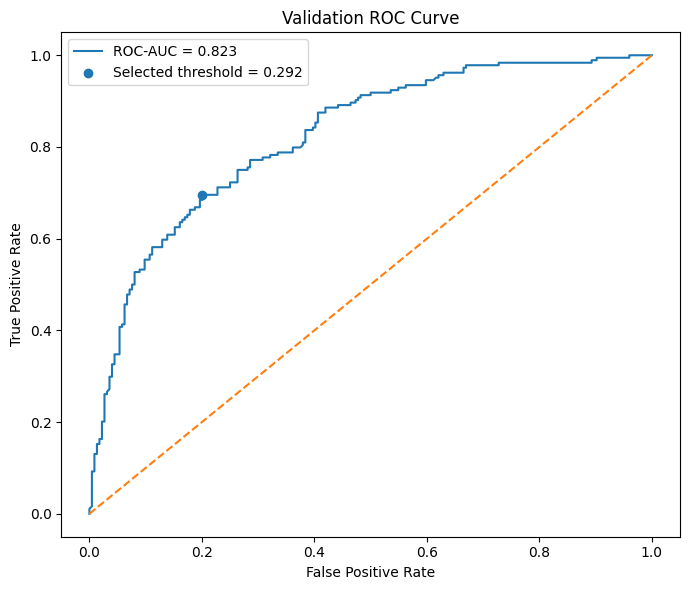

In [49]:
validation_roc_auc = (
    roc_auc_score(
        val_targets,
        val_probabilities,
    )
)


plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    label=(
        f"ROC-AUC = "
        f"{validation_roc_auc:.3f}"
    ),
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

plt.scatter(
    finite_fpr[best_index],
    finite_tpr[best_index],
    label=(
        "Selected threshold = "
        f"{SELECTED_THRESHOLD:.3f}"
    ),
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Validation ROC Curve"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "validation_roc_curve.png",
    dpi=180,
)

plt.show()

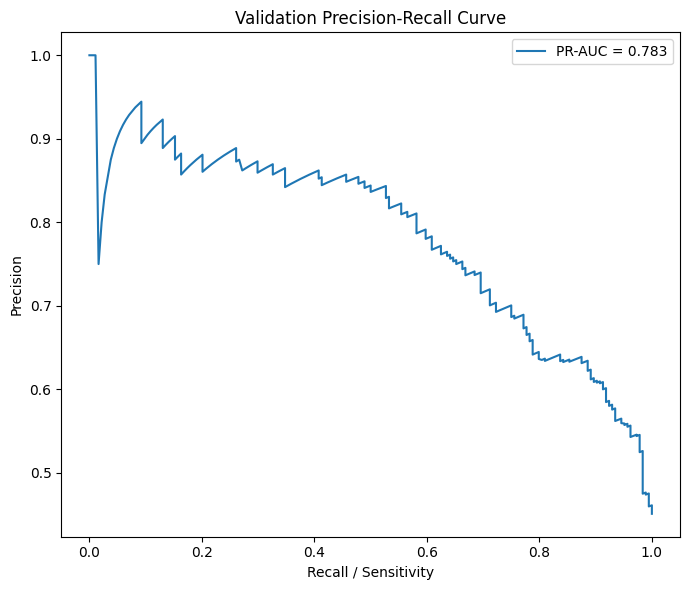

In [50]:
precision_curve, recall_curve, _ = (
    precision_recall_curve(
        val_targets,
        val_probabilities,
    )
)


validation_pr_auc = (
    average_precision_score(
        val_targets,
        val_probabilities,
    )
)


plt.figure(
    figsize=(7, 6)
)

plt.plot(
    recall_curve,
    precision_curve,
    label=(
        f"PR-AUC = "
        f"{validation_pr_auc:.3f}"
    ),
)

plt.xlabel(
    "Recall / Sensitivity"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Validation Precision-Recall Curve"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "validation_precision_recall_curve.png",
    dpi=180,
)

plt.show()

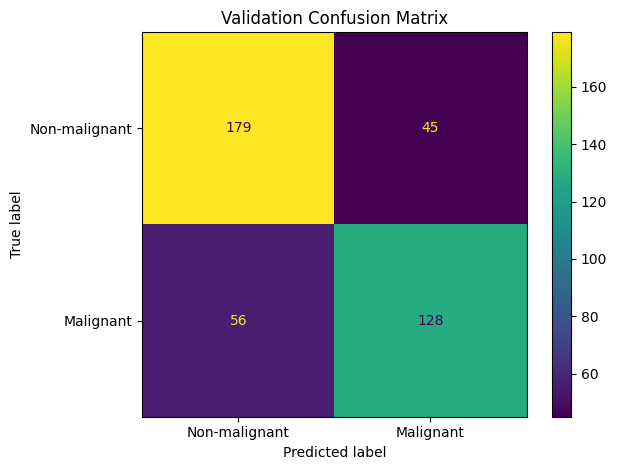

In [51]:
val_predicted_labels = (
    val_probabilities
    >= SELECTED_THRESHOLD
).astype(
    np.int64
)


display = ConfusionMatrixDisplay.from_predictions(
    val_targets,
    val_predicted_labels,
    display_labels=[
        "Non-malignant",
        "Malignant",
    ],
)

display.ax_.set_title(
    "Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "validation_confusion_matrix.png",
    dpi=180,
)

plt.show()

In [52]:
test_dataset = load_split_into_ram(
    dataframe=test_df,
    root_dir=PROJECT_ROOT,
    split_name="Test",
)


test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)


print(
    "Test batches:",
    len(test_loader),
)

print(
    "\nLocked threshold:",
    SELECTED_THRESHOLD
)

Loading Test into RAM:   0%|          | 0/394 [00:00<?, ?it/s]

Test: 394 images loaded
Tensor shape: torch.Size([394, 1024, 640])
RAM usage: 0.48 GiB
Test batches: 99

Locked threshold: 0.29150390625


In [53]:
test_predictions = predict_probabilities(
    model=model,
    loader=test_loader,
    device=device,
    description="Final test inference",
)


test_predictions = (
    test_predictions.merge(
        test_df[
            [
                "image_key",
                "patient_id",
                "pathology",
                "abnormality_type",
            ]
        ],
        on="image_key",
        how="left",
        validate="one_to_one",
    )
)


test_predictions[
    "predicted_label"
] = (
    test_predictions[
        "probability"
    ]
    >= SELECTED_THRESHOLD
).astype(
    np.int64
)


test_predictions.to_csv(
    OUTPUT_DIR
    / "test_predictions.csv",
    index=False,
)


print(
    test_predictions.head()
)

print(
    "\nTest inference complete."
)

print(
    "Predictions saved — "
    "there is no need to rerun inference "
    "for later analyses."
)

Final test inference:   0%|          | 0/99 [00:00<?, ?it/s]

           image_key  target  probability patient_id  pathology  \
0    P_00014_LEFT_CC       1     0.164307    P_00014  MALIGNANT   
1   P_00014_LEFT_MLO       1     0.155029    P_00014  MALIGNANT   
2   P_00019_RIGHT_CC       0     0.164307    P_00019     BENIGN   
3  P_00019_RIGHT_MLO       0     0.644043    P_00019     BENIGN   
4   P_00023_RIGHT_CC       1     0.715820    P_00023  MALIGNANT   

  abnormality_type  predicted_label  
0    calcification                0  
1    calcification                0  
2    calcification                0  
3    calcification                1  
4             mass                1  

Test inference complete.
Predictions saved — there is no need to rerun inference for later analyses.


In [54]:
test_targets = (
    test_predictions[
        "target"
    ].to_numpy()
)

test_probabilities = (
    test_predictions[
        "probability"
    ].to_numpy()
)


FINAL_TEST_METRICS = (
    calculate_metrics(
        targets=test_targets,
        probabilities=test_probabilities,
        threshold=SELECTED_THRESHOLD,
    )
)


with open(
    OUTPUT_DIR
    / "final_test_metrics.json",
    "w",
) as f:

    json.dump(
        FINAL_TEST_METRICS,
        f,
        indent=2,
    )


print(
    "FINAL HELD-OUT TEST RESULTS"
)

print(
    "=" * 50
)

print(
    json.dumps(
        FINAL_TEST_METRICS,
        indent=2,
    )
)

FINAL HELD-OUT TEST RESULTS
{
  "threshold": 0.29150390625,
  "roc_auc": 0.6978929089778146,
  "pr_auc": 0.697765549378006,
  "accuracy": 0.6573604060913706,
  "balanced_accuracy": 0.6512803234501348,
  "precision": 0.6459627329192547,
  "sensitivity": 0.5714285714285714,
  "specificity": 0.7311320754716981,
  "f1": 0.6064139941690962,
  "tn": 155,
  "fp": 57,
  "fn": 78,
  "tp": 104
}


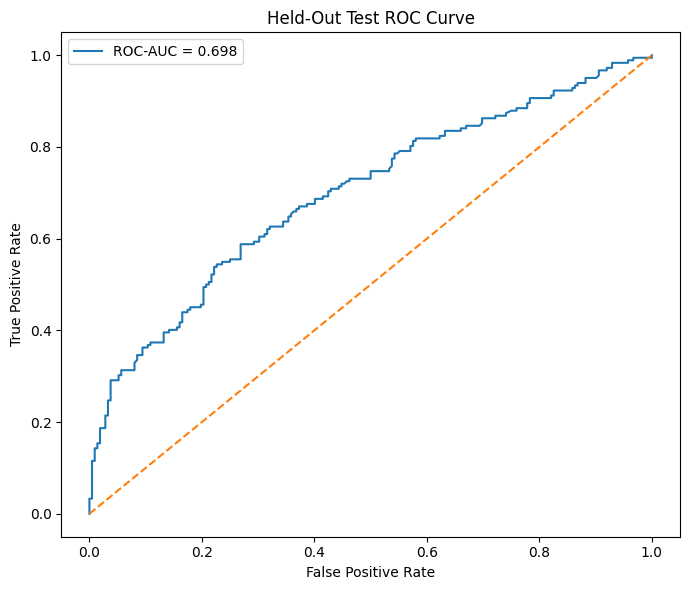

In [55]:
test_fpr, test_tpr, _ = (
    roc_curve(
        test_targets,
        test_probabilities,
    )
)


plt.figure(
    figsize=(7, 6)
)

plt.plot(
    test_fpr,
    test_tpr,
    label=(
        f"ROC-AUC = "
        f"{FINAL_TEST_METRICS['roc_auc']:.3f}"
    ),
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Held-Out Test ROC Curve"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "test_roc_curve.png",
    dpi=180,
)

plt.show()

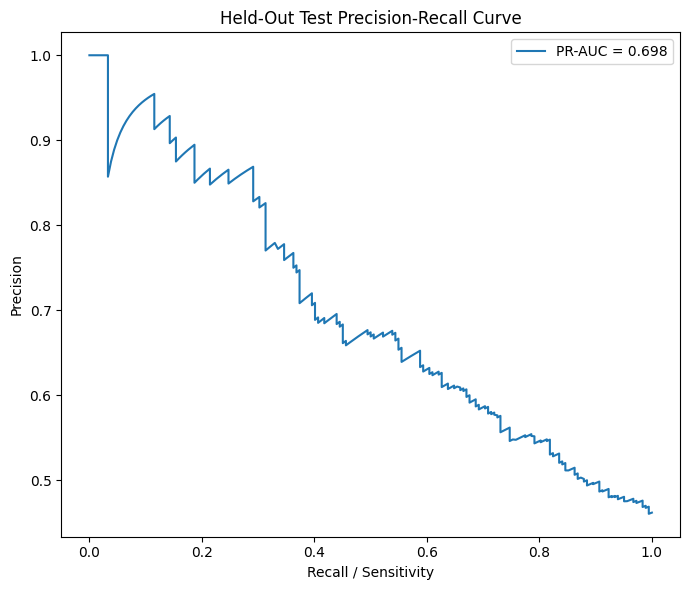

In [56]:
test_precision_curve, test_recall_curve, _ = (
    precision_recall_curve(
        test_targets,
        test_probabilities,
    )
)


plt.figure(
    figsize=(7, 6)
)

plt.plot(
    test_recall_curve,
    test_precision_curve,
    label=(
        f"PR-AUC = "
        f"{FINAL_TEST_METRICS['pr_auc']:.3f}"
    ),
)

plt.xlabel(
    "Recall / Sensitivity"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Held-Out Test Precision-Recall Curve"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "test_precision_recall_curve.png",
    dpi=180,
)

plt.show()

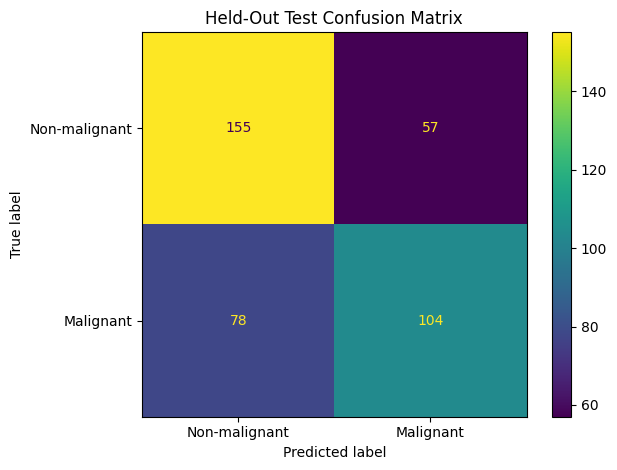

In [59]:
test_predicted_labels = (
    test_predictions[
        "predicted_label"
    ].to_numpy()
)


cm_display = ConfusionMatrixDisplay.from_predictions(
    test_targets,
    test_predicted_labels,
    display_labels=[
        "Non-malignant",
        "Malignant",
    ],
)

cm_display.ax_.set_title(
    "Held-Out Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "test_confusion_matrix.png",
    dpi=180,
)

plt.show()

In [60]:
false_negatives = (
    test_predictions[
        (
            test_predictions["target"]
            == 1
        )
        &
        (
            test_predictions[
                "predicted_label"
            ]
            == 0
        )
    ]
    .sort_values(
        "probability",
        ascending=True,
    )
    .reset_index(
        drop=True
    )
)


false_positives = (
    test_predictions[
        (
            test_predictions["target"]
            == 0
        )
        &
        (
            test_predictions[
                "predicted_label"
            ]
            == 1
        )
    ]
    .sort_values(
        "probability",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


false_negatives.to_csv(
    OUTPUT_DIR
    / "false_negatives.csv",
    index=False,
)


false_positives.to_csv(
    OUTPUT_DIR
    / "false_positives.csv",
    index=False,
)


from IPython.display import display as notebook_display

print(
    "False negatives:",
    len(false_negatives),
)

print(
    "False positives:",
    len(false_positives),
)

print(
    "\nMost confident false negatives:"
)

notebook_display(
    false_negatives.head(10)
)

print(
    "\nMost confident false positives:"
)

notebook_display(
    false_positives.head(10)
)

False negatives: 78
False positives: 57

Most confident false negatives:


,image_key,target,probability,patient_id,pathology,abnormality_type,predicted_label
0,P_01848_RIGHT_MLO,1,0.019867,P_01848,MALIGNANT,mass,0
1,P_01072_LEFT_CC,1,0.031082,P_01072,MALIGNANT,calcification,0
2,P_00057_RIGHT_CC,1,0.035736,P_00057,MALIGNANT,mass,0
3,P_00275_LEFT_MLO,1,0.044769,P_00275,MALIGNANT,calcification,0
4,P_01848_RIGHT_CC,1,0.045197,P_01848,MALIGNANT,mass,0
5,P_00092_LEFT_MLO,1,0.047424,P_00092,MALIGNANT,mass,0
6,P_01043_RIGHT_MLO,1,0.048767,P_01043,MALIGNANT,calcification,0
7,P_00127_RIGHT_MLO,1,0.049408,P_00127,MALIGNANT,calcification,0
8,P_01043_RIGHT_CC,1,0.050415,P_01043,MALIGNANT,calcification,0
9,P_01232_RIGHT_MLO,1,0.052704,P_01232,MALIGNANT,mass,0



Most confident false positives:


,image_key,target,probability,patient_id,pathology,abnormality_type,predicted_label
0,P_01447_RIGHT_CC,0,0.980957,P_01447,BENIGN,mass,1
1,P_00531_RIGHT_MLO,0,0.909180,P_00531,BENIGN,calcification,1
2,P_00026_LEFT_CC,0,0.888672,P_00026,BENIGN,mass,1
3,P_00348_LEFT_MLO,0,0.870605,P_00348,BENIGN,mass,1
4,P_02159_LEFT_MLO,0,0.814453,P_02159,BENIGN,calcification,1
5,P_00100_RIGHT_CC,0,0.804199,P_00100,BENIGN,calcification,1
6,P_00651_RIGHT_MLO,0,0.790039,P_00651,BENIGN,mass,1
7,P_02159_LEFT_CC,0,0.755859,P_02159,BENIGN,calcification,1
8,P_00659_RIGHT_MLO,0,0.687500,P_00659,BENIGN,mass,1
9,P_01249_LEFT_CC,0,0.676758,P_01249,BENIGN,calcification,1


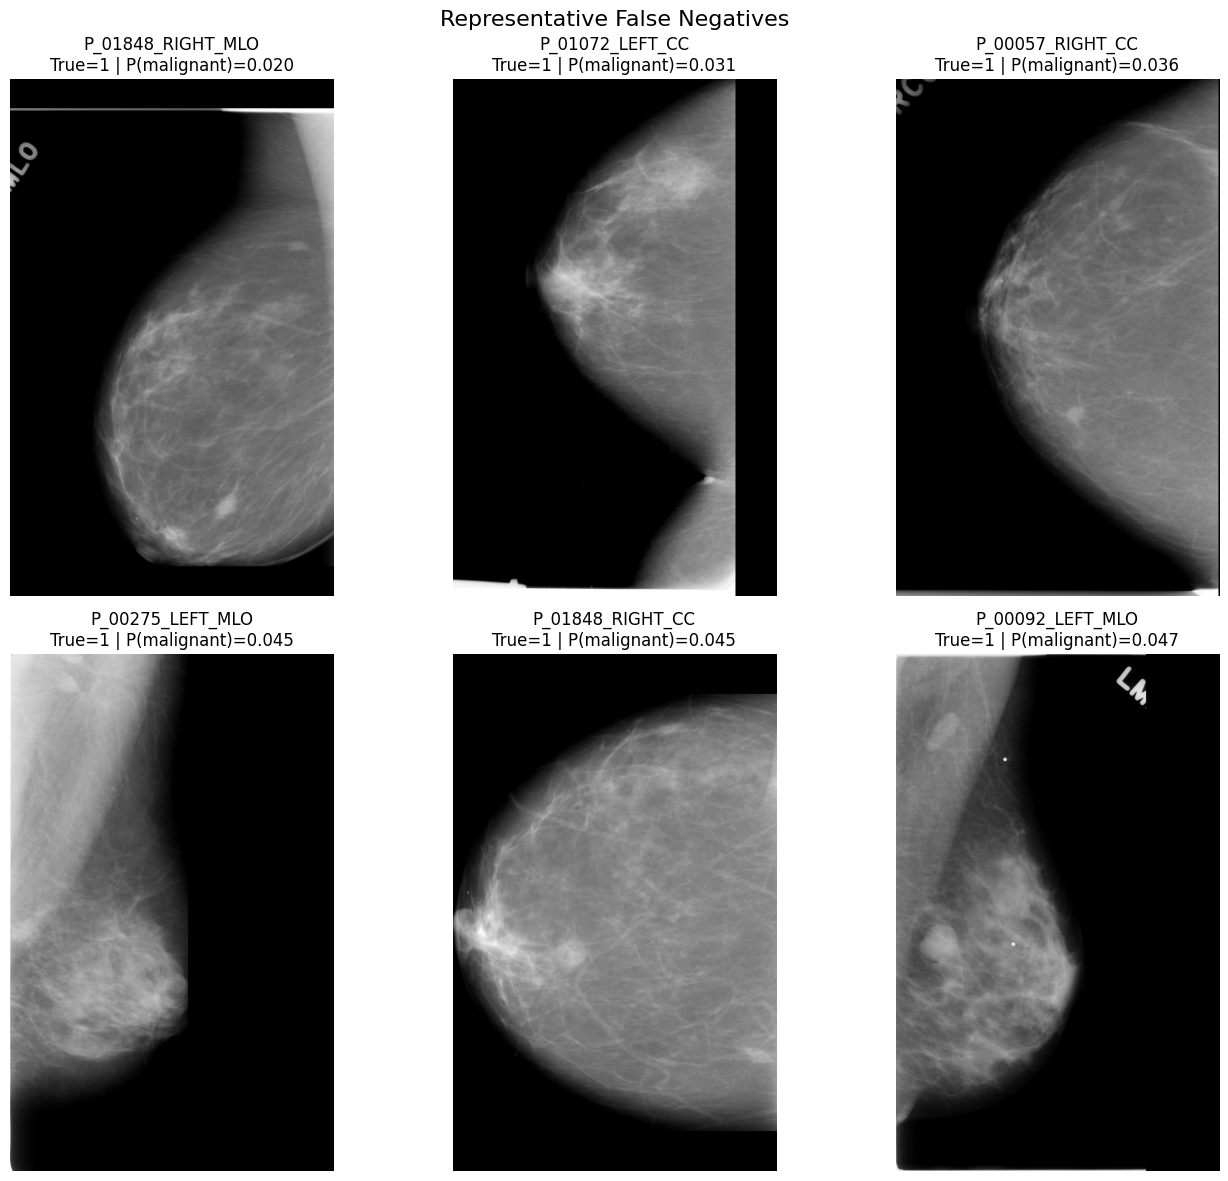

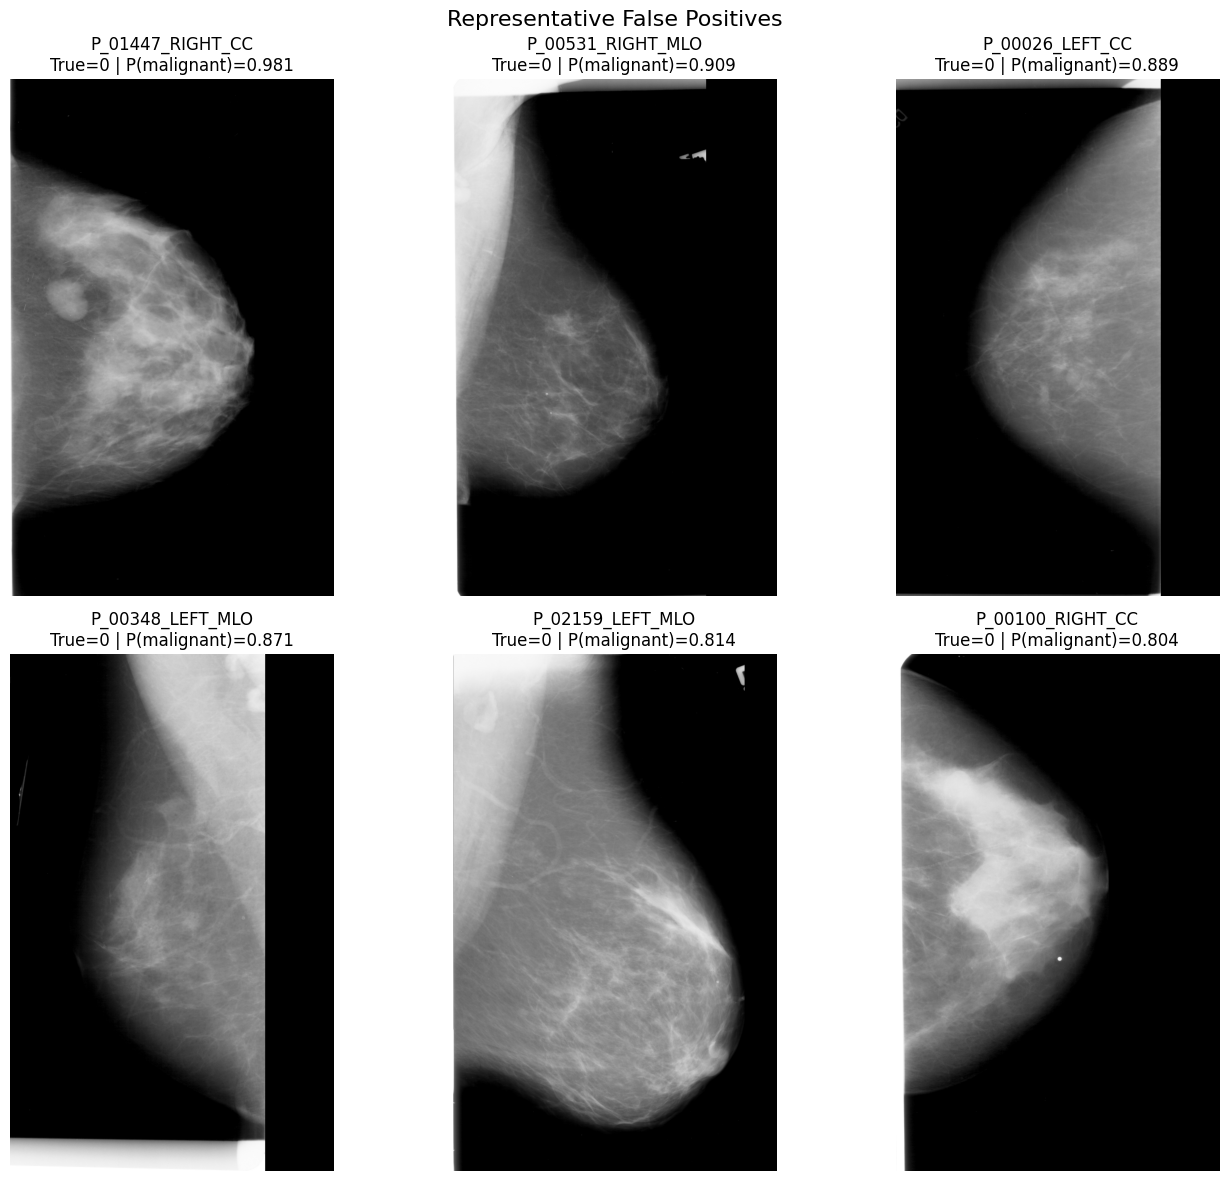

In [61]:
def plot_failure_cases(
    cases,
    root_dir,
    title,
    output_path,
    max_cases=6,
):

    cases = cases.head(
        max_cases
    )

    if len(cases) == 0:

        print(
            f"No cases available for {title}"
        )

        return


    fig, axes = plt.subplots(
        2,
        3,
        figsize=(14, 12),
    )

    axes = axes.flatten()


    for ax in axes:
        ax.axis("off")


    for ax, row in zip(
        axes,
        cases.itertuples(
            index=False
        ),
    ):

        source_row = test_df.loc[
            test_df["image_key"]
            == row.image_key
        ].iloc[0]

        image = np.load(
            root_dir
            / source_row["npy_path"]
        )

        ax.imshow(
            image,
            cmap="gray",
        )

        ax.set_title(
            f"{row.image_key}\n"
            f"True={row.target} | "
            f"P(malignant)="
            f"{row.probability:.3f}"
        )

        ax.axis("off")


    fig.suptitle(
        title,
        fontsize=16,
    )

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()


plot_failure_cases(
    cases=false_negatives,
    root_dir=PROJECT_ROOT,
    title=(
        "Representative False Negatives"
    ),
    output_path=(
        FIGURE_DIR
        / "false_negative_examples.png"
    ),
)


plot_failure_cases(
    cases=false_positives,
    root_dir=PROJECT_ROOT,
    title=(
        "Representative False Positives"
    ),
    output_path=(
        FIGURE_DIR
        / "false_positive_examples.png"
    ),
)

In [62]:
def bootstrap_patient_metrics(
    predictions_df,
    threshold,
    n_bootstrap=1000,
    seed=42,
):

    rng = np.random.default_rng(
        seed
    )

    patient_groups = {
        patient_id:
            group.copy()
        for patient_id, group
        in predictions_df.groupby(
            "patient_id"
        )
    }

    patient_ids = np.array(
        list(
            patient_groups.keys()
        )
    )


    bootstrap_results = []


    for _ in tqdm(
        range(n_bootstrap),
        desc="Patient bootstrap",
    ):

        sampled_patients = (
            rng.choice(
                patient_ids,
                size=len(patient_ids),
                replace=True,
            )
        )


        sample = pd.concat(
            [
                patient_groups[
                    patient_id
                ]
                for patient_id
                in sampled_patients
            ],
            ignore_index=True,
        )


        y_true = sample[
            "target"
        ].to_numpy()

        y_prob = sample[
            "probability"
        ].to_numpy()


        # AUC is undefined if a bootstrap
        # sample contains only one class.
        if np.unique(
            y_true
        ).size < 2:
            continue


        metrics = calculate_metrics(
            targets=y_true,
            probabilities=y_prob,
            threshold=threshold,
        )

        bootstrap_results.append(
            metrics
        )


    bootstrap_df = pd.DataFrame(
        bootstrap_results
    )


    metric_names = [
        "roc_auc",
        "pr_auc",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "sensitivity",
        "specificity",
        "f1",
    ]


    intervals = {}


    for metric in metric_names:

        intervals[metric] = {
            "estimate": (
                FINAL_TEST_METRICS[
                    metric
                ]
            ),
            "ci_95_low": float(
                bootstrap_df[
                    metric
                ].quantile(
                    0.025
                )
            ),
            "ci_95_high": float(
                bootstrap_df[
                    metric
                ].quantile(
                    0.975
                )
            ),
        }


    return (
        bootstrap_df,
        intervals,
    )


bootstrap_df, confidence_intervals = (
    bootstrap_patient_metrics(
        predictions_df=test_predictions,
        threshold=SELECTED_THRESHOLD,
        n_bootstrap=1000,
        seed=SEED,
    )
)


bootstrap_df.to_csv(
    OUTPUT_DIR
    / "patient_bootstrap_metrics.csv",
    index=False,
)


with open(
    OUTPUT_DIR
    / "confidence_intervals.json",
    "w",
) as f:

    json.dump(
        confidence_intervals,
        f,
        indent=2,
    )


print(
    json.dumps(
        confidence_intervals,
        indent=2,
    )
)

Patient bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

{
  "roc_auc": {
    "estimate": 0.6978929089778146,
    "ci_95_low": 0.6314640956643658,
    "ci_95_high": 0.7605702282927573
  },
  "pr_auc": {
    "estimate": 0.697765549378006,
    "ci_95_low": 0.6085053603149029,
    "ci_95_high": 0.7801652824565526
  },
  "accuracy": {
    "estimate": 0.6573604060913706,
    "ci_95_low": 0.5983729293367105,
    "ci_95_high": 0.7114975238261564
  },
  "balanced_accuracy": {
    "estimate": 0.6512803234501348,
    "ci_95_low": 0.5937960145594628,
    "ci_95_high": 0.7038174122073578
  },
  "precision": {
    "estimate": 0.6459627329192547,
    "ci_95_low": 0.5577860017246334,
    "ci_95_high": 0.7374301675977654
  },
  "sensitivity": {
    "estimate": 0.5714285714285714,
    "ci_95_low": 0.4827499566799515,
    "ci_95_high": 0.6538461538461539
  },
  "specificity": {
    "estimate": 0.7311320754716981,
    "ci_95_low": 0.664937931532225,
    "ci_95_high": 0.8
  },
  "f1": {
    "estimate": 0.6064139941690962,
    "ci_95_low": 0.5282956597546548,
  

In [64]:
evaluation_summary = {
    "model": (
        "ResNet-50"
    ),

    "checkpoint": (
        "resnet50_layer4_best.pth"
    ),

    "input_resolution": [
        TARGET_HEIGHT,
        TARGET_WIDTH,
    ],

    "checkpoint_selection": {
        "dataset": "validation",
        "metric": "ROC-AUC",
        "roc_auc": float(
            checkpoint[
                "val_metrics"
            ]["roc_auc"]
        ),
    },

    "threshold_selection": {
        "dataset": "validation",
        "method": (
            "maximum Youden J"
        ),
        "threshold": (
            SELECTED_THRESHOLD
        ),
    },

    "final_test_metrics": (
        FINAL_TEST_METRICS
    ),

    "confidence_intervals": (
        confidence_intervals
    ),

    "test_samples": int(
        len(test_predictions)
    ),

    "notes": (
        "Research prototype. "
        "The model and classification "
        "threshold were selected without "
        "using held-out test performance."
    ),
}


with open(
    OUTPUT_DIR
    / "evaluation_summary.json",
    "w",
) as f:

    json.dump(
        evaluation_summary,
        f,
        indent=2,
    )


print(
    json.dumps(
        evaluation_summary,
        indent=2,
    )
)

{
  "model": "ResNet-50",
  "checkpoint": "resnet50_layer4_best.pth",
  "input_resolution": [
    1024,
    640
  ],
  "checkpoint_selection": {
    "dataset": "validation",
    "metric": "ROC-AUC",
    "roc_auc": 0.8227387422360248
  },
  "threshold_selection": {
    "dataset": "validation",
    "method": "maximum Youden J",
    "threshold": 0.29150390625
  },
  "final_test_metrics": {
    "threshold": 0.29150390625,
    "roc_auc": 0.6978929089778146,
    "pr_auc": 0.697765549378006,
    "accuracy": 0.6573604060913706,
    "balanced_accuracy": 0.6512803234501348,
    "precision": 0.6459627329192547,
    "sensitivity": 0.5714285714285714,
    "specificity": 0.7311320754716981,
    "f1": 0.6064139941690962,
    "tn": 155,
    "fp": 57,
    "fn": 78,
    "tp": 104
  },
  "confidence_intervals": {
    "roc_auc": {
      "estimate": 0.6978929089778146,
      "ci_95_low": 0.6314640956643658,
      "ci_95_high": 0.7605702282927573
    },
    "pr_auc": {
      "estimate": 0.697765549378006,
 

In [65]:
print(
    "CLASSIFIER EVALUATION OUTPUTS"
)

print(
    "=" * 60
)


for path in sorted(
    OUTPUT_DIR.rglob("*")
):

    if path.is_file():

        print(
            path.relative_to(
                OUTPUT_DIR
            )
        )


zip_path = shutil.make_archive(
    "/kaggle/working/"
    "classifier_evaluation",
    "zip",
    OUTPUT_DIR,
)


print(
    "\nEvaluation archive:"
)

print(
    zip_path
)

CLASSIFIER EVALUATION OUTPUTS
confidence_intervals.json
evaluation_summary.json
false_negatives.csv
false_positives.csv
figures/false_negative_examples.png
figures/false_positive_examples.png
figures/test_confusion_matrix.png
figures/test_precision_recall_curve.png
figures/test_roc_curve.png
figures/validation_confusion_matrix.png
figures/validation_precision_recall_curve.png
figures/validation_roc_curve.png
final_test_metrics.json
patient_bootstrap_metrics.csv
test_predictions.csv
threshold_selection.json
validation_predictions.csv

Evaluation archive:
/kaggle/working/classifier_evaluation.zip


In [68]:
subgroup_rows = []
from IPython.display import display as notebook_display

for abnormality_type, group in test_predictions.groupby("abnormality_type"):

    targets = group["target"].to_numpy()
    probabilities = group["probability"].to_numpy()

    if np.unique(targets).size < 2:
        print(
            f"Skipping {abnormality_type}: "
            "only one class present."
        )
        continue

    metrics = calculate_metrics(
        targets=targets,
        probabilities=probabilities,
        threshold=SELECTED_THRESHOLD,
    )

    subgroup_rows.append(
        {
            "abnormality_type": abnormality_type,
            "n": len(group),
            **metrics,
        }
    )


subgroup_metrics_df = pd.DataFrame(
    subgroup_rows
)

subgroup_metrics_df.to_csv(
    OUTPUT_DIR / "test_metrics_by_abnormality_type.csv",
    index=False,
)

notebook_display(
    subgroup_metrics_df[
        [
            "abnormality_type",
            "n",
            "roc_auc",
            "pr_auc",
            "accuracy",
            "sensitivity",
            "specificity",
            "f1",
        ]
    ]
)

print("\nSaved:")
print(
    OUTPUT_DIR
    / "test_metrics_by_abnormality_type.csv"
)

,abnormality_type,n,roc_auc,pr_auc,accuracy,sensitivity,specificity,f1
0,calcification,216,0.676034,0.688759,0.634259,0.520000,0.732759,0.568306
1,mass,170,0.724201,0.711361,0.688235,0.636364,0.731183,0.649007
2,mass+calcification,8,0.666667,0.826190,0.625000,0.600000,0.666667,0.666667



Saved:
/kaggle/working/classifier_evaluation/test_metrics_by_abnormality_type.csv


In [69]:
import shutil

zip_path = shutil.make_archive(
    "/kaggle/working/classifier_evaluation",
    "zip",
    OUTPUT_DIR,
)

print(zip_path)

/kaggle/working/classifier_evaluation.zip
